# Univariate Analysis

In [3]:
# Download the necessary libraries
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

# Load the data
clean_data = pd.read_excel("customers_sales_with_dxf_data.xlsx")
clean_data.head(5)

,customer_name,customer_branch,file_name,order_quantity,bounding_box_width,bounding_box_height,cutting_length,num_holes
0,MetalForm SA,Frankfurt Branch,Geo (1).DXF,1600,1600.219048,305.140135,3438.024977,0
1,AutoParts AG,Munich Branch,Geo (10).DXF,9650,853.830000,333.401400,3217.207505,5
2,PrecisionCut GmbH,Stuttgart Branch,Geo (11).DXF,7800,164.000000,145.120000,1742.517642,7
3,PrecisionCut GmbH,Stuttgart Branch,Geo (15).DXF,4000,193.800891,138.442589,1302.774283,2
4,AutoParts AG,Berlin Branch,Geo (12).DXF,8800,937.150697,74.006665,2764.783512,11


## Overview over numerical data

In [4]:
print(clean_data.describe())
print(clean_data.shape)

       order_quantity  bounding_box_width  bounding_box_height  \
count       75.000000           75.000000            75.000000   
mean      7630.666667          678.365861           246.687604   
std       4794.189144          572.388352           288.000042   
min        500.000000           31.495106            12.109000   
25%       4000.000000          173.262228            70.313000   
50%       7650.000000          454.029112           131.505377   
75%       9050.000000         1150.193570           312.833986   
max      19700.000000         1968.901094          1193.261380   

       cutting_length   num_holes  
count       75.000000   75.000000  
mean      3046.774269    9.213333  
std       3930.615806   26.006908  
min        100.961326    0.000000  
25%        775.298742    0.000000  
50%       1745.589881    4.000000  
75%       3711.432839    8.000000  
max      26007.870470  219.000000  
(75, 8)


# Individual Analysis of all Attributes

### Customers

        customer_name  number_of_orders  share_of_orders
0         AutoPart AG                 3         4.000000
1        AutoParts AG                29        38.666667
2        MetalForm SA                12        16.000000
3        Metalform SA                 1         1.333333
4   PrecisionCut GmbH                19        25.333333
5  TechFab Industries                11        14.666667

sum of orders:  75
highest number of orders:  29 by customer:  AutoParts AG


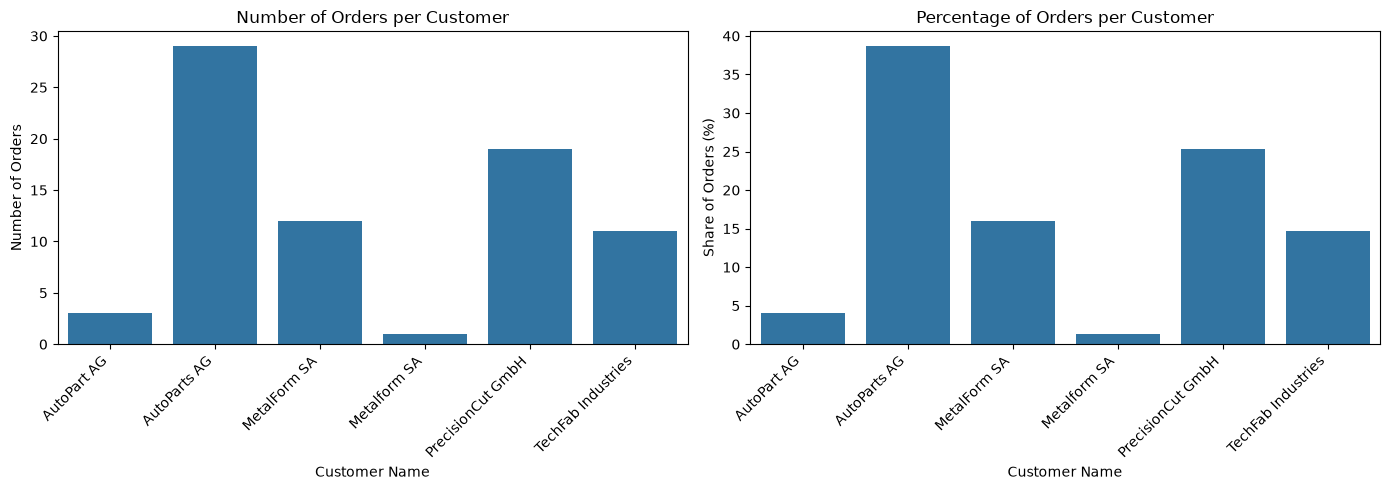

In [5]:
# Create alphabetically sorted DataFrame with customer names and their order counts and shares
customer_df = (
    clean_data['customer_name']
    .dropna()
    .value_counts()
    .rename_axis("customer_name")
    .reset_index(name="number_of_orders")
)
customer_df["share_of_orders"] = customer_df["number_of_orders"] / customer_df["number_of_orders"].sum() * 100
customer_df = customer_df.sort_values("customer_name", ascending=True).reset_index(drop=True)
print(customer_df)
print()

# Print the sum and highest number of orders of a customer
print("sum of orders: ", customer_df["number_of_orders"].sum())
print("highest number of orders: ", customer_df["number_of_orders"].max(), "by customer: ", customer_df.loc[customer_df["number_of_orders"].idxmax(), "customer_name"])

# Plot the number and share of orders per customer in bar charts
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=customer_df, x="customer_name", y="number_of_orders", ax=axes[0])
# Formating
axes[0].set_xticks(range(len(customer_df)))
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha="right")
axes[0].set_ylabel("Number of Orders")
axes[0].set_xlabel("Customer Name")
axes[0].set_title("Number of Orders per Customer")

sns.barplot(data=customer_df, x="customer_name", y="share_of_orders", ax=axes[1])
# Formating
axes[1].set_xticks(range(len(customer_df)))
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha="right")
axes[1].set_ylabel("Share of Orders (%)")
axes[1].set_xlabel("Customer Name")
axes[1].set_title("Percentage of Orders per Customer")
# Show plots
plt.tight_layout()
plt.show()

## Customer Branch

    customer_branch  number_of_orders  share_of_orders
0     Berlin Branch                14        18.666667
1  Frankfurt Branch                13        17.333333
2    Hamburg Branch                11        14.666667
3     Munich Branch                18        24.000000
4  Stuttgart Branch                19        25.333333

sum of orders:  75
highest number of orders:  19 by branch:  Stuttgart Branch


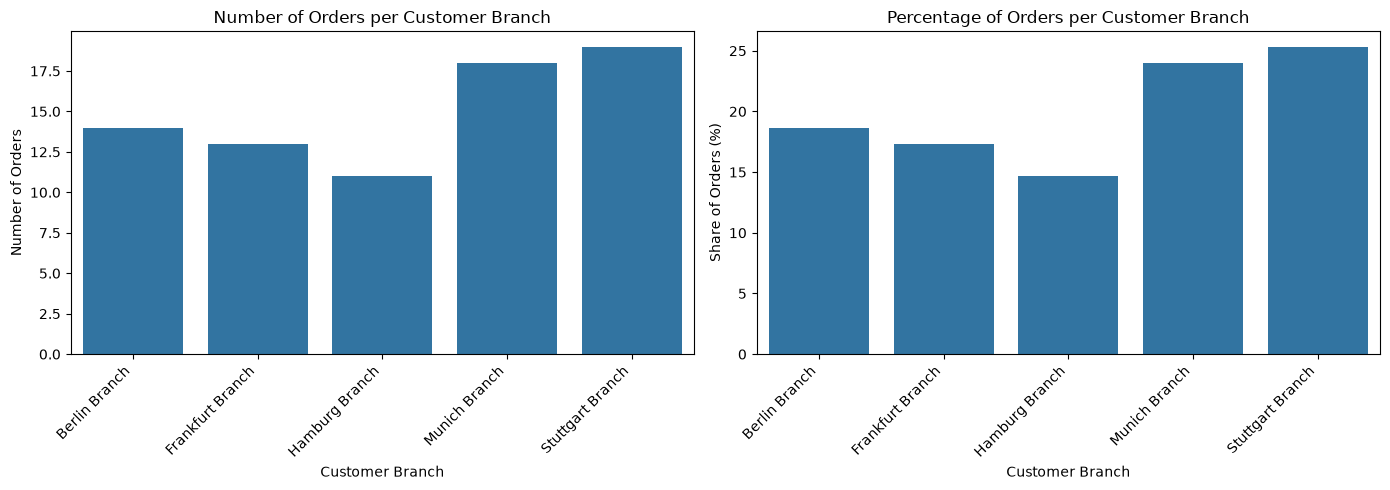

In [6]:
# Create alphabetically sorted DataFrame with customer branches and their order counts and shares
branch_df = (
    clean_data['customer_branch']
    .dropna()
    .value_counts()
    .rename_axis("customer_branch")
    .reset_index(name="number_of_orders")
)
branch_df["share_of_orders"] = branch_df["number_of_orders"] / branch_df["number_of_orders"].sum() * 100
branch_df = branch_df.sort_values("customer_branch", ascending=True).reset_index(drop=True)
print(branch_df)

# Print the sum and highest number of orders of a customer branch

print()
print("sum of orders: ", branch_df["number_of_orders"].sum())
print("highest number of orders: ", branch_df["number_of_orders"].max(), "by branch: ", branch_df.loc[branch_df["number_of_orders"].idxmax(), "customer_branch"])

# Plot the number and share of orders per customer in bar charts
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=branch_df, x="customer_branch", y="number_of_orders", ax=axes[0])
# Formating
axes[0].set_xticks(range(len(branch_df)))
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha="right")
axes[0].set_ylabel("Number of Orders")
axes[0].set_xlabel("Customer Branch")
axes[0].set_title("Number of Orders per Customer Branch")

sns.barplot(data=branch_df, x="customer_branch", y="share_of_orders", ax=axes[1])
# Formating
axes[1].set_xticks(range(len(branch_df)))
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha="right")
axes[1].set_ylabel("Share of Orders (%)")
axes[1].set_xlabel("Customer Branch")
axes[1].set_title("Percentage of Orders per Customer Branch")
# Show plots
plt.tight_layout()
plt.show()

## Files / Parts

Analysis shows:
Each of the 75 DXF-Files is ordered in exactly one order.

In [7]:
# Create alphabetically sorted DataFrame with file names and their order counts and shares
file_df = (
    clean_data['file_name']
    .dropna()
    .value_counts()
    .rename_axis("file_name")
    .reset_index(name="number_of_orders")
)
file_df = file_df.sort_values("file_name", ascending=True).reset_index(drop=True)
print(file_df)
print()
# Print the sum, highest and lowest number of orders of a file
print("sum of orders: ", file_df["number_of_orders"].sum())
print("highest number of orders: ", file_df["number_of_orders"].max())
print("lowest number of orders: ", file_df["number_of_orders"].min())



       file_name  number_of_orders
0    Geo (1).DXF                 1
1   Geo (10).DXF                 1
2   Geo (11).DXF                 1
3   Geo (12).DXF                 1
4   Geo (13).DXF                 1
..           ...               ...
70  Geo (78).DXF                 1
71  Geo (79).DXF                 1
72   Geo (8).DXF                 1
73  Geo (80).DXF                 1
74   Geo (9).DXF                 1

[75 rows x 2 columns]

sum of orders:  75
highest number of orders:  1
lowest number of orders:  1


## Order Quantity

In [8]:
# Create a DataFrame with order quantities and their number of appearances
quantity = ( 
    clean_data['order_quantity']
    .dropna()
    .value_counts()
    .rename_axis("order_quantity")
    .reset_index(name="number_of_appearance")
    .sort_values("order_quantity", ascending=True)
    .reset_index(drop=True))

# Print the sum and highest number of appearances of an order quantity
print("sum of appearances: ", quantity["number_of_appearance"].sum())
print("highest number of appearances: ", quantity["number_of_appearance"].max(), ", e.g. by order quantity: ", quantity.loc[quantity["number_of_appearance"].idxmax(), "order_quantity"])
print()

# Calculate quantity statistics
quantities = clean_data["order_quantity"].dropna()
q1, q3 = quantities.quantile(0.25), quantities.quantile(0.75)
iqr = q3 - q1

quantity_statistics = pd.Series({
    "count": quantities.count(),
    "missing": clean_data["order_quantity"].isna().sum(),
    "mean": quantities.mean(),
    "median": quantities.median(),
    "mode": quantities.mode().iloc[0] if not quantities.mode().empty else np.nan,
    "q25": q1,
    "q75": q3,
    "min": quantities.min(),
    "max": quantities.max(),
    "range": quantities.max() - quantities.min(),
    "iqr": iqr,
    "variance": quantities.var(),
    "std": quantities.std(),
    "skewness": quantities.skew(),
    "kurtosis": quantities.kurt(),
    "n_outliers_iqr": ((quantities < q1 - 1.5 * iqr) | (quantities > q3 + 1.5 * iqr)).sum(),
})

sum of appearances:  75
highest number of appearances:  3 , e.g. by order quantity:  4000



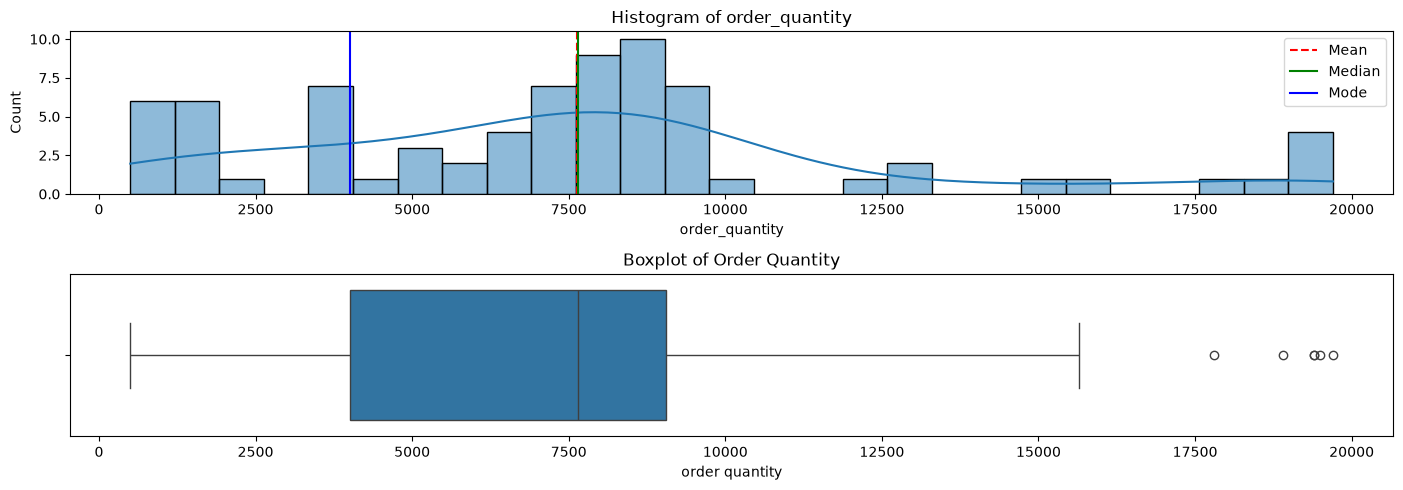

In [9]:
# Visualile the order quantity statistics in a histogram and boxplot
fig, axes = plt.subplots(2, 1, figsize=(14, 5))

sns.histplot(quantities, kde=True, ax=axes[0], binwidth=700)
axes[0].axvline(quantity_statistics["mean"], color="red", linestyle="--", label="Mean")
axes[0].axvline(quantity_statistics["median"], color="green", linestyle="-", label="Median")
axes[0].axvline(quantity_statistics["mode"], color="blue", linestyle="-", label="Mode")
axes[0].set_title("Histogram of order_quantity")
axes[0].legend()


sns.boxplot(x=quantities, ax=axes[1])
axes[1].set_title("Boxplot of Order Quantity")
axes[1].set_xlabel("order quantity")

plt.tight_layout()

## Bounding Box Width

In [10]:
# Create a Data Frame with bounding box widths and their number of appearances 
width = ( 
    clean_data['bounding_box_width']
    .dropna()
    .value_counts()
    .rename_axis("bounding_box_width")
    .reset_index(name="number_of_appearance")
    .sort_values("bounding_box_width", ascending=True)
    .reset_index(drop=True))

# Print the sum and highest number of appearances of a bounding box width
print("sum of appearances: ", width["number_of_appearance"].sum())
print("highest number of appearances: ", width["number_of_appearance"].max(), ", e.g. by bounding box width: ", width.loc[width["number_of_appearance"].idxmax(), "bounding_box_width"])
print()

# Calculate width statistics
widths = clean_data["bounding_box_width"].dropna()
q1, q3 = widths.quantile(0.25), widths.quantile(0.75)
iqr = q3 - q1
mean, std = widths.mean(), widths.std()

width_statistics = pd.Series({
    "count": widths.count(),
    "missing": clean_data["bounding_box_width"].isna().sum(),
    "mean": mean,
    "median": widths.median(),
    "mode": widths.mode().iloc[0] if not widths.mode().empty else np.nan,
    "q25": q1,
    "q75": q3,
    "min": widths.min(),
    "max": widths.max(),
    "range": widths.max() - widths.min(),
    "iqr": iqr,
    "variance": widths.var(),
    "std": std,
    "skewness": widths.skew(),
    "kurtosis": widths.kurt(),
    "n_outliers_iqr": ((widths < q1 - 1.5 * iqr) | (widths > q3 + 1.5 * iqr)).sum(),
})

sum of appearances:  75
highest number of appearances:  1 , e.g. by bounding box width:  31.4951055212



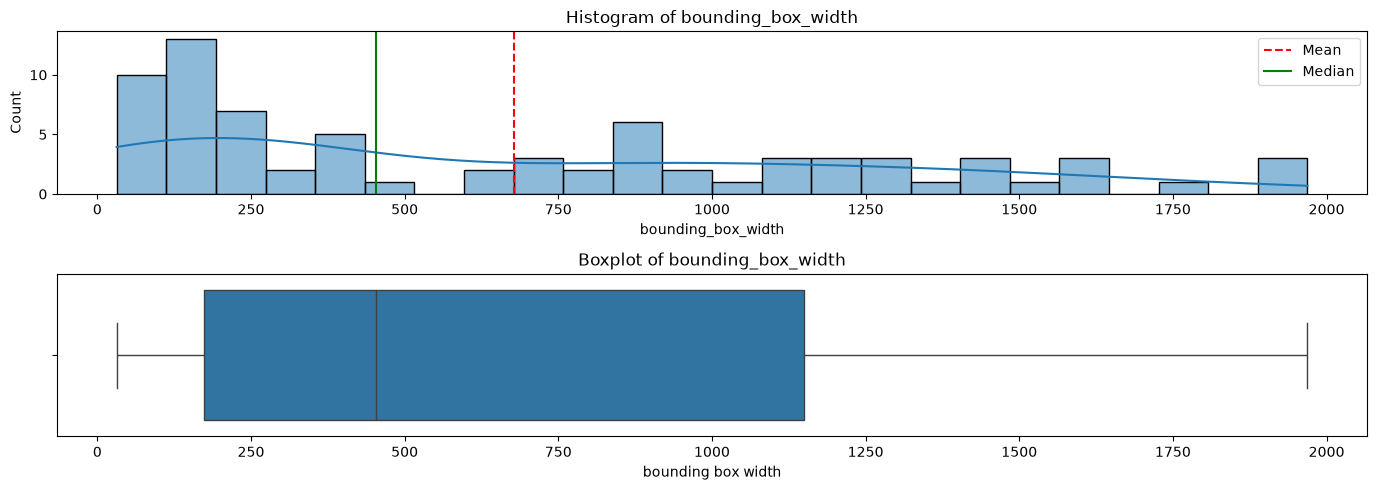

In [11]:
# Visualise the bounding box width statistics in a histogram and box plot
fig, axes = plt.subplots(2, 1, figsize=(14, 5))

sns.histplot(widths, kde=True, ax=axes[0], binwidth=80)
# Formating
axes[0].axvline(width_statistics["mean"], color="red", linestyle="--", label="Mean")
axes[0].axvline(width_statistics["median"], color="green", linestyle="-", label="Median")
axes[0].set_title("Histogram of bounding_box_width")
axes[0].legend()


sns.boxplot(x=widths, ax=axes[1])
# Formating
axes[1].set_title("Boxplot of bounding_box_width")
axes[1].set_xlabel("bounding box width")

plt.tight_layout()

## Bounding Box Heights

In [12]:
# Create a Data Frame with bounding box heights and their number of appearances
height = ( 
    clean_data['bounding_box_height']
    .dropna()
    .value_counts()
    .rename_axis("bounding_box_height")
    .reset_index(name="number_of_appearance")
    .sort_values("bounding_box_height", ascending=True)
    .reset_index(drop=True))

# Print the sum and highest number of appearances of a bounding box height
print("sum of appearances: ", height["number_of_appearance"].sum())
print("highest number of appearances: ", height["number_of_appearance"].max(), ", e.g. by bounding box height: ", height.loc[height["number_of_appearance"].idxmax(), "bounding_box_height"])
print()

# Calculate height statistics
heights = clean_data["bounding_box_height"].dropna()
q1, q3 = heights.quantile(0.25), heights.quantile(0.75)
iqr = q3 - q1
mean, std = heights.mean(), heights.std()   # Stichprobenwerte (ddof=1)

height_statistics = pd.Series({
    "count": heights.count(),
    "missing": clean_data["bounding_box_height"].isna().sum(),
    "mean": mean,
    "median": heights.median(),
    "mode": heights.mode().iloc[0] if not heights.mode().empty else np.nan,
    "q25": q1,
    "q75": q3,
    "min": heights.min(),
    "max": heights.max(),
    "range": heights.max() - heights.min(),
    "iqr": iqr,
    "variance": heights.var(),
    "std": std,
    "skewness": heights.skew(),
    "kurtosis": heights.kurt(),
    "n_outliers_iqr": ((heights < q1 - 1.5 * iqr) | (heights > q3 + 1.5 * iqr)).sum(),
})

sum of appearances:  75
highest number of appearances:  1 , e.g. by bounding box height:  12.109



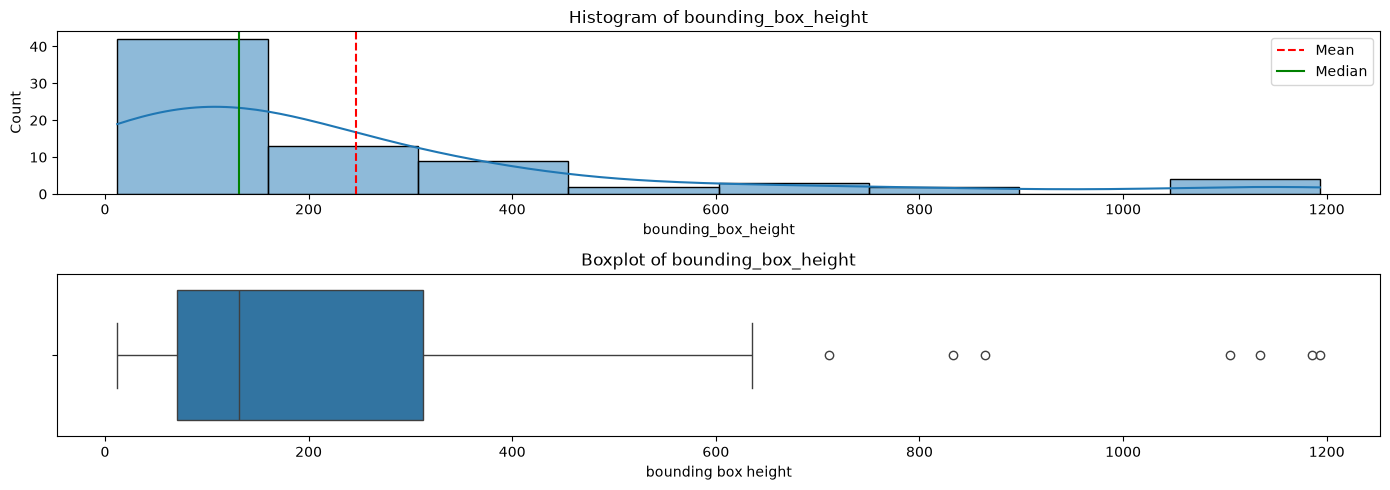

In [13]:
fig, axes = plt.subplots(2, 1, figsize=(14, 5))

sns.histplot(heights, kde=True, ax=axes[0], binwidth=140)
axes[0].axvline(height_statistics["mean"], color="red", linestyle="--", label="Mean")
axes[0].axvline(height_statistics["median"], color="green", linestyle="-", label="Median")
axes[0].set_title("Histogram of bounding_box_height")
axes[0].legend()


sns.boxplot(x=heights, ax=axes[1])
axes[1].set_title("Boxplot of bounding_box_height")
axes[1].set_xlabel("bounding box height")

plt.tight_layout()

## Cutting Length

In [14]:
# Create a Data Frame with cutting lengths and their number of appearances
cutting_length = ( 
    clean_data['cutting_length']
    .dropna()
    .value_counts()
    .rename_axis("cutting_length")
    .reset_index(name="number_of_appearance")
    .sort_values("cutting_length", ascending=True)
    .reset_index(drop=True))

# Print the sum and highest number of appearances of a cutting length
print("sum of appearances: ", cutting_length["number_of_appearance"].sum())
print("highest number of appearances: ", cutting_length["number_of_appearance"].max(), ", e.g. by cutting length: ", cutting_length.loc[cutting_length["number_of_appearance"].idxmax(), "cutting_length"])
print()

# Calculate cutting length statistics
cutting_lengths = clean_data["cutting_length"].dropna()
q1, q3 = cutting_lengths.quantile(0.25), cutting_lengths.quantile(0.75)
iqr = q3 - q1
mean, std = cutting_lengths.mean(), cutting_lengths.std() 

cutting_length_statistics = pd.Series({
    "count": cutting_lengths.count(),
    "missing": clean_data["cutting_length"].isna().sum(),
    "mean": mean,
    "median": cutting_lengths.median(),
    "mode": cutting_lengths.mode().iloc[0] if not cutting_lengths.mode().empty else np.nan,
    "q25": q1,
    "q75": q3,
    "min": cutting_lengths.min(),
    "max": cutting_lengths.max(),
    "range": cutting_lengths.max() - cutting_lengths.min(),
    "iqr": iqr,
    "variance": cutting_lengths.var(),
    "std": std,
    "skewness": cutting_lengths.skew(),
    "kurtosis": cutting_lengths.kurt(),
    "n_outliers_iqr": ((cutting_lengths < q1 - 1.5 * iqr) | (cutting_lengths > q3 + 1.5 * iqr)).sum(),
})

sum of appearances:  75
highest number of appearances:  1 , e.g. by cutting length:  100.9613258690418



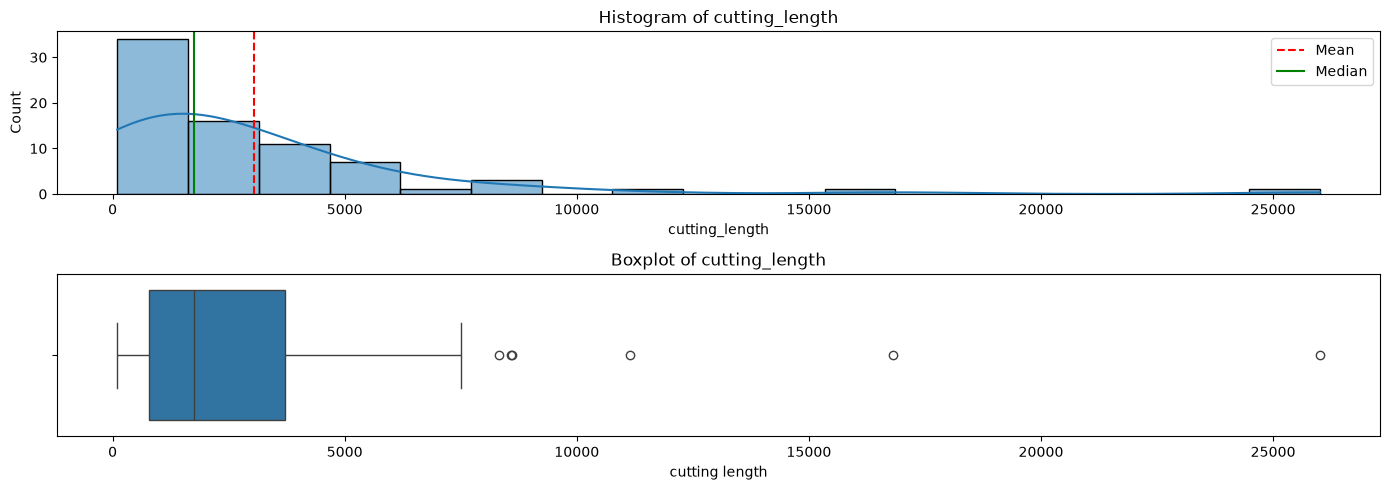

In [15]:
# Visualise the cutting length statistics in a histogram and boxplot
fig, axes = plt.subplots(2, 1, figsize=(14, 5))

sns.histplot(cutting_lengths, kde=True, ax=axes[0], binwidth=1500)
# Formating
axes[0].axvline(cutting_length_statistics["mean"], color="red", linestyle="--", label="Mean")
axes[0].axvline(cutting_length_statistics["median"], color="green", linestyle="-", label="Median")
axes[0].set_title("Histogram of cutting_length")
axes[0].legend()


sns.boxplot(x=cutting_lengths, ax=axes[1])
# Formating
axes[1].set_title("Boxplot of cutting_length")
axes[1].set_xlabel("cutting length")
plt.tight_layout()

## Number of Holes

In [16]:
# Create a Data Frame with number of holes and their number of appearances
hole = ( 
    clean_data['num_holes']
    .dropna()
    .value_counts()
    .rename_axis("num_holes")
    .reset_index(name="number_of_appearance")
    .sort_values("num_holes", ascending=True)
    .reset_index(drop=True))

# Print the sum and highest number of appearances of a number of holes
print("sum of appearances: ", hole["number_of_appearance"].sum())
print("highest number of appearances: ", hole["number_of_appearance"].max(), ", e.g. by number of holes: ", hole.loc[hole["number_of_appearance"].idxmax(), "num_holes"])
print()

# Calculate number of holes statistics
num_holes = clean_data["num_holes"].dropna()
q1, q3 = num_holes.quantile(0.25), num_holes.quantile(0.75)
iqr = q3 - q1
mean, std = num_holes.mean(), num_holes.std()   # Stichprobenwerte (ddof=1)

num_holes_statistics = pd.Series({
    "count": num_holes.count(),
    "missing": clean_data["num_holes"].isna().sum(),
    "mean": mean,
    "median": num_holes.median(),
    "mode": num_holes.mode().iloc[0] if not num_holes.mode().empty else np.nan,
    "q25": q1,
    "q75": q3,
    "min": num_holes.min(),
    "max": num_holes.max(),
    "range": num_holes.max() - num_holes.min(),
    "iqr": iqr,
    "variance": num_holes.var(),
    "std": std,
    "skewness": num_holes.skew(),
    "kurtosis": num_holes.kurt(),
    "n_outliers_iqr": ((num_holes < q1 - 1.5 * iqr) | (num_holes > q3 + 1.5 * iqr)).sum(),
})

sum of appearances:  75
highest number of appearances:  20 , e.g. by number of holes:  0



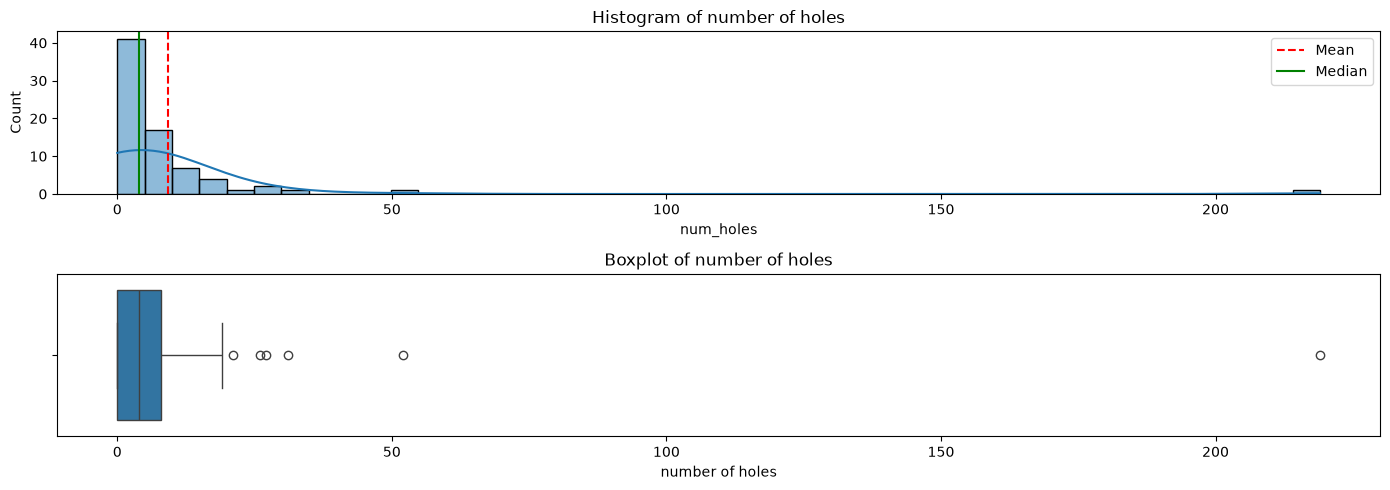

In [17]:
# Visualise the number of holes statistics in a histogram and boxplot
fig, axes = plt.subplots(2, 1, figsize=(14, 5))

sns.histplot(num_holes, kde=True, ax=axes[0], binwidth=5)
# Formating
axes[0].axvline(num_holes_statistics["mean"], color="red", linestyle="--", label="Mean")
axes[0].axvline(num_holes_statistics["median"], color="green", linestyle="-", label="Median")
axes[0].set_title("Histogram of number of holes")
axes[0].legend()


sns.boxplot(x=num_holes, ax=axes[1])
# Formating
axes[1].set_title("Boxplot of number of holes")
axes[1].set_xlabel("number of holes")
plt.tight_layout()